# ESP-CSI Multi-Room People Detection — `rawData2`

New dataset collected with the **receiver in a new position (living room)**.
File names encode **where the people were**: a number in front of a room letter =
how many people stood in that room.

| file | meaning | total people |
|---|---|---|
| `2l3b.csv` | 2 in **l**iving room + 3 in **b**edroom | 5 |
| `4l1b.csv` | 4 in living room + 1 in bedroom | 5 |
| `4l1k.csv` | 4 in living room + 1 in **k**itchen | 5 |
| `5l.csv`    | 5 in living room | 5 |

> **Key property:** every recording has **exactly 5 people in total** — only their
> *room distribution* changes. So a model cannot cheat with "how much motion /
> how many bodies overall"; it must react to *where* the attenuation happens
> (living room dominates the line of sight to the receiver, bedroom/kitchen are
> one wall further away).

## Goals (same pipeline as the first notebook, applied to rawData2)
1. Extract & clean the CSI amplitude data from each CSV.
2. **Visually / statistically compare the four recordings** — are they different at all?
3. **Train several AI models** on sliding-window features and **compare metrics**,
   under two evaluation schemes:
   - *Random window split* (optimistic — windows from the same recording leak into both sides),
   - **Leave-One-Recording-Out (LORO)** cross-validation (honest — the test recording
     is never seen during training).

## Step 0 — Setup: imports, file naming convention, configuration

In [1]:
# ---- imports (standard data-science stack) ----
import hashlib
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, confusion_matrix)

# ---- configuration ----
RAW_DIR      = Path('rawData2')                  # folder with the 4 CSV files
RECORDINGS   = ['2l3b', '4l1b', '4l1k', '5l']   # label 0..3 (order matters!)
ROOM_NAMES   = {'l': 'living room', 'b': 'bedroom', 'k': 'kitchen'}
CLASS_ORDER  = RECORDINGS                        # used consistently below
CLASS_COLORS = ['#4c72b0', '#dd8452', '#55a868', '#c44e52']

def parse_people(stem):
    """'2l3b' -> {'l': 2, 'b': 3, 'k': 0}  (number in front of each room letter)."""
    counts = {r: 0 for r in ROOM_NAMES}
    for n, room in re.findall(r'(\d+)([lbk])', stem):
        counts[room] = int(n)
    return counts

PEOPLE = {r: parse_people(r) for r in RECORDINGS}
for r in RECORDINGS:
    p = PEOPLE[r]
    print(f'{r:5s} -> living room: {p["l"]}  bedroom: {p["b"]}  kitchen: {p["k"]}'
          f'   (total {sum(p.values())} people)')

# ESP32 CSI "data" column layout (verified on rawData, re-checked on rawData2 in Step 3):
#   256 numbers = 2 antenna chains x 64 subcarrier bins x 2 (I, Q)
#   bin 0 unused | bins 1-26 lower sideband | 27-37 pilots/DC | 38-63 UPPER sideband (kept)
UPPER_BINS = np.arange(38, 64)      # 26 subcarriers used for everything below

WINDOW_FRAMES = 100                 # ~1.2 s of CSI per sample (84 fps average)
STRIDE_FRAMES = 50                  # windows overlap by 50%
RANDOM_STATE  = 42                  # makes splits / models reproducible
plt.rcParams['figure.dpi'] = 100    # crisper plots
print('\nSetup OK — numpy', np.__version__, '| pandas', pd.__version__)

2l3b  -> living room: 2  bedroom: 3  kitchen: 0   (total 5 people)
4l1b  -> living room: 4  bedroom: 1  kitchen: 0   (total 5 people)
4l1k  -> living room: 4  bedroom: 0  kitchen: 1   (total 5 people)
5l    -> living room: 5  bedroom: 0  kitchen: 0   (total 5 people)

Setup OK — numpy 2.2.6 | pandas 2.3.3


## Step 1 — File integrity: checksums and capture metadata
Identical files would make two "classes" indistinguishable by construction — check first.

In [2]:
# Compute an MD5 checksum of each file: identical files -> identical checksum.
checksums = {}
for name in RECORDINGS:
    path = RAW_DIR / f'{name}.csv'
    checksums[name] = hashlib.md5(path.read_bytes()).hexdigest()
    print(f'{name:6s}  {checksums[name]}  ({path.stat().st_size/1e6:.1f} MB)')

duplicates = [(a, b) for i, a in enumerate(RECORDINGS)
              for b in RECORDINGS[i+1:] if checksums[a] == checksums[b]]
if duplicates:
    for a, b in duplicates:
        print(f'\n*** WARNING: "{a}.csv" and "{b}.csv" are BYTE-IDENTICAL files! ***')
else:
    print('\nAll four recordings are distinct files. Good to go.')

2l3b    bd65cade130311ffc747310d72168a4c  (4.2 MB)
4l1b    534afcea1eed8ab3da3dc4946e27d0fb  (4.1 MB)
4l1k    39f5c6a1ff9939dead9cd7defe646cc5  (3.7 MB)
5l      bc7407eaa66ec01a5eea13678922d6a5  (4.2 MB)

All four recordings are distinct files. Good to go.


## Step 2 — Load the CSI frames
Same fast parser as the first notebook: the `data` column is a string of 256 int8
values (2 chains x 64 bins x I/Q). We keep the chain-averaged amplitude
`|H| = sqrt(I^2 + Q^2)` per subcarrier bin.

In [3]:
def load_csi(name):
    """Read one CSV of CSI frames -> (metadata DataFrame, amp (N,64), raw iq (N,2,64,2))."""
    meta = pd.read_csv(RAW_DIR / f'{name}.csv')

    # The 'data' column is a string like "[0,0,-14,3,...]".
    # Fast trick: strip brackets, split on commas -> wide table of 256 int columns.
    wide = (meta['data'].str.strip('[]')
                 .str.split(',', expand=True)
                 .iloc[:, :256]                      # safety: drop any stray column
                 .to_numpy(np.int8))                 # values fit in signed 8-bit

    iq  = wide.reshape(len(meta), 2, 64, 2).astype(np.float32)  # (frame, chain, bin, I/Q)
    amp = np.hypot(iq[..., 0], iq[..., 1]).mean(axis=1)          # (frame, 64) avg of 2 chains
    return meta, amp, iq

frames = {}   # frames[name] = {'meta':..., 'amp': (N,64), 'iq': (N,2,64,2)}
for name in RECORDINGS:
    t = time.time()
    meta, amp, iq = load_csi(name)
    frames[name] = {'meta': meta, 'amp': amp, 'iq': iq}
    print(f'{name:6s}: {len(meta):5d} frames, {amp.shape[1]} subcarrier bins ({time.time()-t:.2f}s)')

# Sanity check on capture metadata (channel / rate must match the working setup)
for name in RECORDINGS:
    m = frames[name]['meta']
    dur = (m['timestamp'].iloc[-1] - m['timestamp'].iloc[0]) / 1e6   # µs -> s
    print(f"{name:6s}: channel={m['channel'].unique()}  wifi rate={m['rate'].unique()} "
          f"(11 = OFDM MCS0, good)  duration={dur:.0f}s  avg={len(m)/dur:.0f} frames/s")

2l3b  :  5055 frames, 64 subcarrier bins (0.21s)


4l1b  :  5008 frames, 64 subcarrier bins (0.22s)
4l1k  :  4477 frames, 64 subcarrier bins (0.19s)


5l    :  5081 frames, 64 subcarrier bins (0.22s)
2l3b  : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=84 frames/s
4l1b  : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=84 frames/s
4l1k  : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=75 frames/s
5l    : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=85 frames/s


## Step 3 — Subcarrier structure: confirm the usable band
Before comparing recordings we re-check *which hardware bins carry signal* in this
dataset (bins 38-63 = upper sideband, same as rawData).

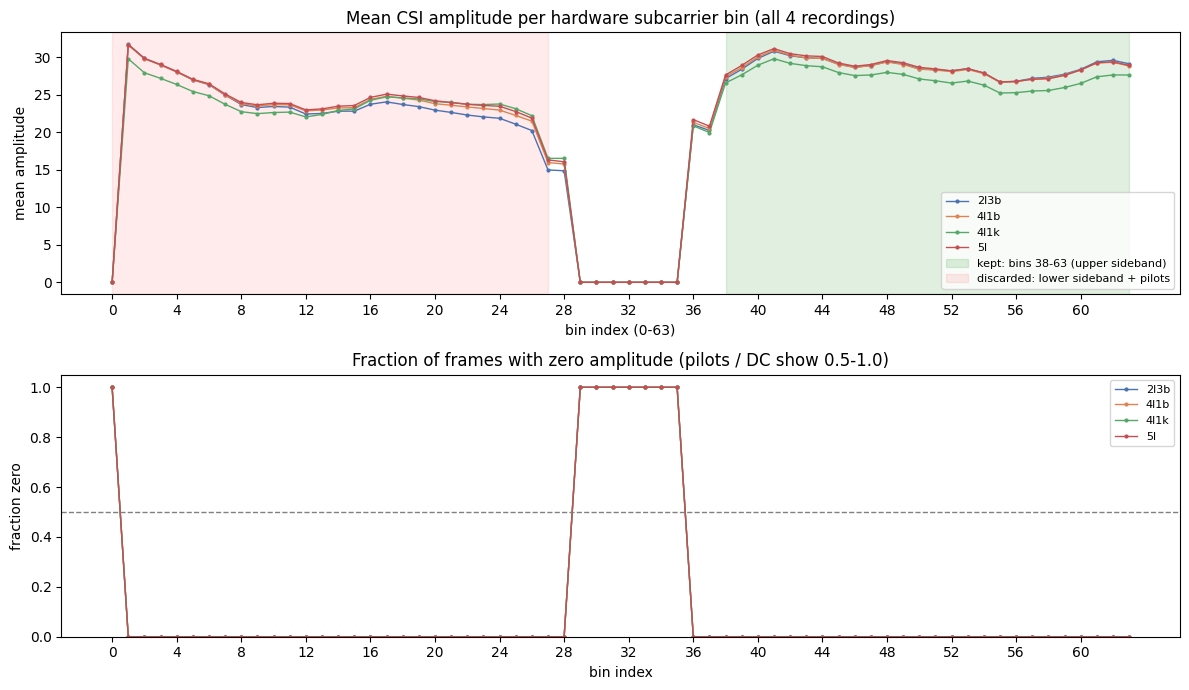

Same structure as rawData: bins 1-26 (lower) and 27-37 (pilots/DC) unusable,
bins 38-63 (upper sideband) carry the signal -> keep those 26 subcarriers.


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# --- top plot: mean amplitude per bin, one line per recording ---
ax = axes[0]
for name, color in zip(RECORDINGS, CLASS_COLORS):
    ax.plot(frames[name]['amp'].mean(axis=0), '.-', color=color, label=name, lw=1, ms=4)
ax.axvspan(UPPER_BINS[0], UPPER_BINS[-1], color='green', alpha=0.12,
           label=f'kept: bins {UPPER_BINS[0]}-{UPPER_BINS[-1]} (upper sideband)')
ax.axvspan(0, 27, color='red', alpha=0.08, label='discarded: lower sideband + pilots')
ax.set_title('Mean CSI amplitude per hardware subcarrier bin (all 4 recordings)')
ax.set_xlabel('bin index (0-63)'); ax.set_ylabel('mean amplitude'); ax.legend(fontsize=8)
ax.set_xticks(range(0, 64, 4))

# --- bottom plot: fraction of frames where the bin is exactly zero ---
ax = axes[1]
for name, color in zip(RECORDINGS, CLASS_COLORS):
    frac_zero = (frames[name]['amp'] == 0).mean(axis=0)
    ax.plot(frac_zero, '.-', color=color, label=name, lw=1, ms=4)
ax.axhline(0.5, ls='--', c='gray', lw=1)
ax.set_title('Fraction of frames with zero amplitude (pilots / DC show 0.5-1.0)')
ax.set_xlabel('bin index'); ax.set_ylabel('fraction zero'); ax.legend(fontsize=8)
ax.set_xticks(range(0, 64, 4)); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

print('Same structure as rawData: bins 1-26 (lower) and 27-37 (pilots/DC) unusable,')
print('bins 38-63 (upper sideband) carry the signal -> keep those 26 subcarriers.')

In [5]:
# From now on every frame is represented by ONLY the 26 upper-sideband amplitudes.
MAX_GAP_US = 200_000      # 200 ms: larger gaps split the stream into "sessions"

for name in RECORDINGS:
    frames[name]['upper'] = frames[name]['amp'][:, UPPER_BINS]
    U  = frames[name]['upper']
    ts = frames[name]['meta']['timestamp'].to_numpy(np.int64)

    keep = U.mean(axis=1) > 2.0                    # (1) drop all-zero/dead frames
    dt   = np.diff(ts, prepend=ts[0] + 1)          # time since previous frame, µs
    keep = keep & (dt < MAX_GAP_US)                # (2) drop first frame after a long gap

    frames[name]['U']    = U[keep]                 # (n_clean, 26)
    frames[name]['rssi'] = frames[name]['meta']['rssi'].to_numpy(np.float32)[keep]
    frames[name]['ts']   = ts[keep]
    print(f'{name:6s}: kept {keep.sum():5d} / {len(keep)} frames '
          f'(dropped {len(keep)-keep.sum()} bad/gap-boundary)')

SC_LABELS = [f'+{i}' for i in range(2, 2 + len(UPPER_BINS))]

2l3b  : kept  5054 / 5055 frames (dropped 1 bad/gap-boundary)
4l1b  : kept  5006 / 5008 frames (dropped 2 bad/gap-boundary)
4l1k  : kept  4475 / 4477 frames (dropped 2 bad/gap-boundary)
5l    : kept  5081 / 5081 frames (dropped 0 bad/gap-boundary)


## Step 4 — Are the recordings different? (visual + statistical comparison)

### 4a — Time-frequency heatmaps: amplitude of the 26 subcarriers over the 60 s session

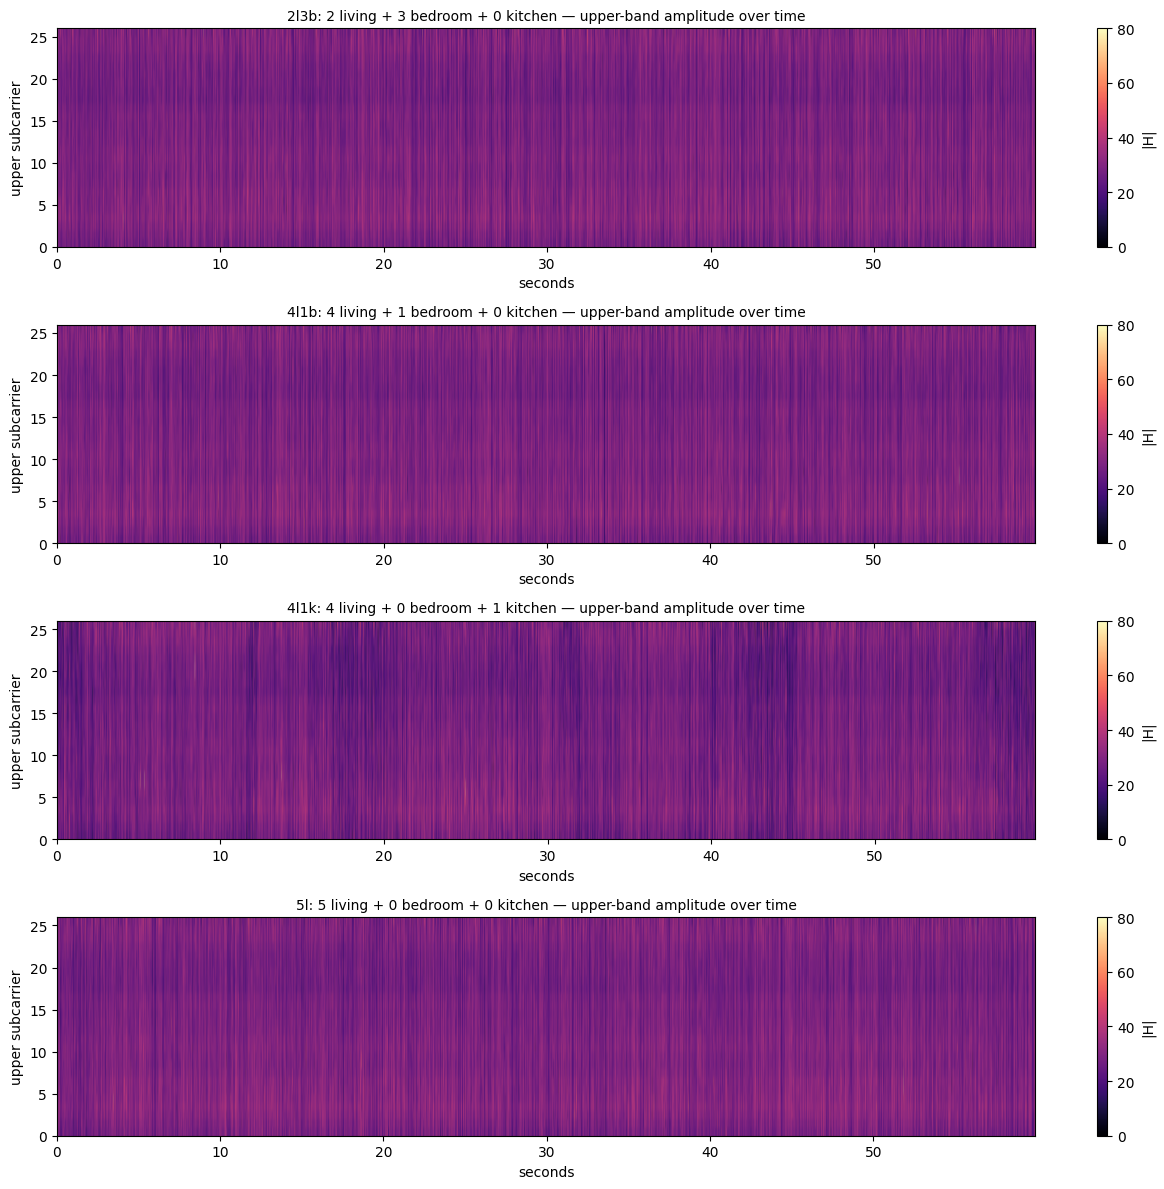

Look for: overall brightness (attenuation), shimmer speed (motion), and how
many subcarriers are "lit" — these differ between room distributions.


In [6]:
def time_axis_seconds(f):
    """Convert timestamps (µs) to seconds since recording start."""
    return (f['ts'] - f['ts'][0]) / 1e6

fig, axes = plt.subplots(len(RECORDINGS), 1, figsize=(13, 3.0 * len(RECORDINGS)))
for ax, name, color in zip(axes, RECORDINGS, CLASS_COLORS):
    f = frames[name]
    t = time_axis_seconds(f)
    img = ax.imshow(f['U'].T, aspect='auto', origin='lower', cmap='magma',
                    extent=[t[0], t[-1], 0, len(UPPER_BINS)], vmin=0, vmax=80)
    p = PEOPLE[name]
    ax.set_ylabel('upper subcarrier')
    ax.set_title(f'{name}: {p["l"]} living + {p["b"]} bedroom + {p["k"]} kitchen '
                 f'— upper-band amplitude over time', fontsize=10)
    ax.set_xlabel('seconds')
    plt.colorbar(img, ax=ax, label='|H|')
plt.tight_layout(); plt.show()
print('Look for: overall brightness (attenuation), shimmer speed (motion), and how')
print('many subcarriers are "lit" — these differ between room distributions.')

### 4b — Temporal signals: mean amplitude and windowed std (motion indicator)

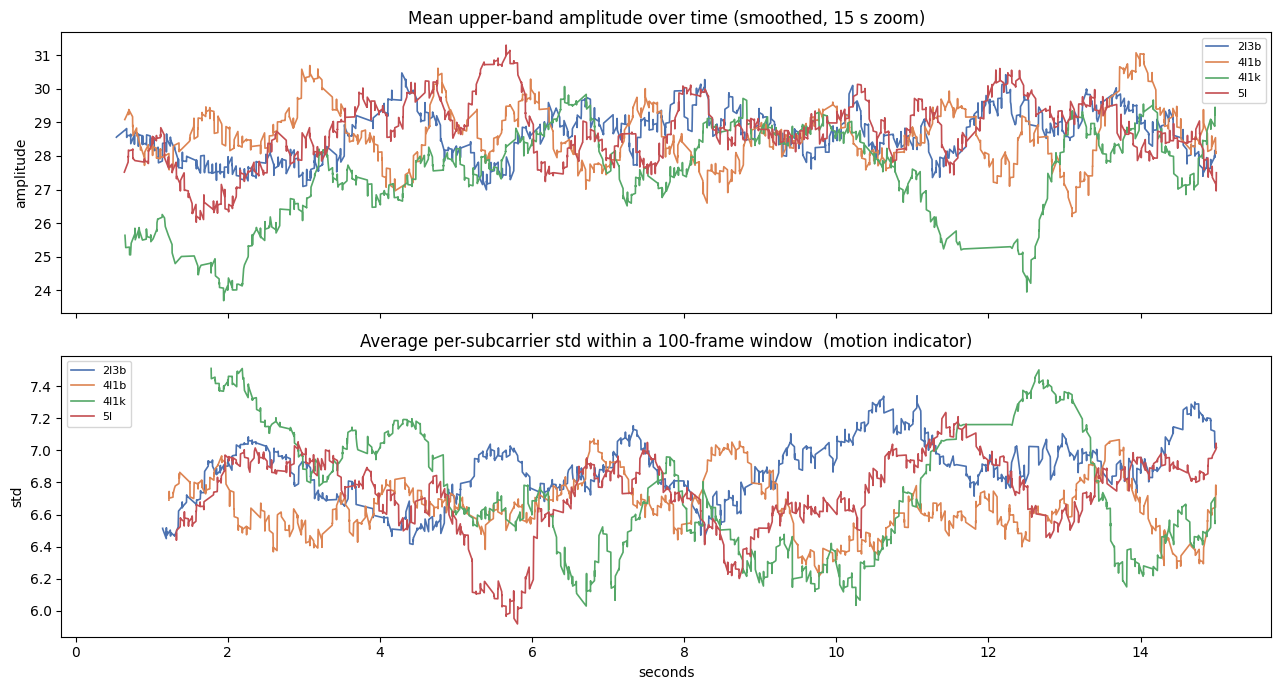

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for name, color in zip(RECORDINGS, CLASS_COLORS):
    f = frames[name]
    t = time_axis_seconds(f)
    mask = t < 15                                        # zoom on first 15 seconds
    roll = pd.Series(f['U'].mean(axis=1)).rolling(50).mean()   # smooth, 50 frames
    axes[0].plot(t[mask], roll.to_numpy()[mask], color=color, lw=1.2, label=name)

    # temporal std inside a 100-frame sliding window = "how much the channel moves"
    wstd = pd.DataFrame(f['U']).rolling(WINDOW_FRAMES).std().mean(axis=1).to_numpy()
    axes[1].plot(t[mask], wstd[mask], color=color, lw=1.2, label=name)

axes[0].set_title('Mean upper-band amplitude over time (smoothed, 15 s zoom)')
axes[0].set_ylabel('amplitude'); axes[0].legend(fontsize=8)
axes[1].set_title('Average per-subcarrier std within a 100-frame window  (motion indicator)')
axes[1].set_ylabel('std'); axes[1].set_xlabel('seconds'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4c — Distribution of the two key statistics + summary table

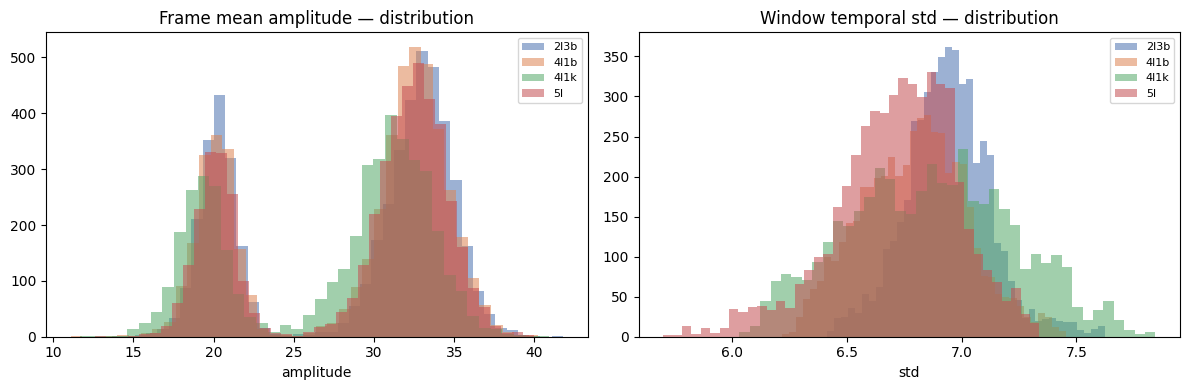

Per-recording summary (all four have 5 people total — only the room mix differs):


,people,frames,mean_amp,amp_std,motion_std,rssi_mean,rssi_std
recording,,,,,,,
2l3b,2l+3b+0k,5054,28.67,6.30,6.94,-70.8,0.6
4l1b,4l+1b+0k,5006,28.63,6.12,6.79,-71.0,0.7
4l1k,4l+0b+1k,4475,27.28,6.05,6.86,-72.8,2.1
5l,5l+0b+0k,5081,28.76,6.03,6.72,-71.0,0.8


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats_rows = []
for name, color in zip(RECORDINGS, CLASS_COLORS):
    f = frames[name]
    mean_amp = f['U'].mean(axis=1)
    wstd = pd.DataFrame(f['U']).rolling(WINDOW_FRAMES).std().mean(axis=1).dropna().to_numpy()
    axes[0].hist(mean_amp, bins=40, alpha=0.55, color=color, label=name)
    axes[1].hist(wstd, bins=40, alpha=0.55, color=color, label=name)
    stats_rows.append(dict(
        recording=name,
        people=f'{PEOPLE[name]["l"]}l+{PEOPLE[name]["b"]}b+{PEOPLE[name]["k"]}k',
        frames=len(f['U']),
        mean_amp=round(float(mean_amp.mean()), 2),
        amp_std=round(float(mean_amp.std()), 2),
        motion_std=round(float(wstd.mean()), 2),
        rssi_mean=round(float(f['rssi'].mean()), 1),
        rssi_std=round(float(f['rssi'].std()), 1)))
axes[0].set_title('Frame mean amplitude — distribution'); axes[0].set_xlabel('amplitude')
axes[1].set_title('Window temporal std — distribution');  axes[1].set_xlabel('std')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

stats = pd.DataFrame(stats_rows).set_index('recording')
print('Per-recording summary (all four have 5 people total — only the room mix differs):')
stats

## Step 5 — Sliding-window feature extraction
Same feature recipe as the first notebook: each 100-frame (~1.2 s) window becomes a
106-dim vector — mean, std, range and frame-to-frame-diff std over the 26 kept
subcarriers, plus 2 RSSI statistics.

In [9]:
def window_features(U, rssi):
    """Split one cleaned recording into windows; return (n_windows, 106) feature matrix."""
    rows = []
    for s in range(0, len(U) - WINDOW_FRAMES + 1, STRIDE_FRAMES):
        w = U[s:s + WINDOW_FRAMES]                    # (100, 26) amplitude window
        d = np.diff(w, axis=0)                        # frame-to-frame change = motion
        rows.append(np.concatenate([
            w.mean(axis=0),                           # 26 features
            w.std(axis=0),                            # 26
            w.max(axis=0) - w.min(axis=0),            # 26
            d.std(axis=0),                            # 26
            [rssi[s:s + WINDOW_FRAMES].mean(),        #  2
             rssi[s:s + WINDOW_FRAMES].std()],
        ]))
    return np.asarray(rows, np.float32)

X_list, y_list, g_list = [], [], []
for k, name in enumerate(RECORDINGS):
    F = window_features(frames[name]['U'], frames[name]['rssi'])
    X_list.append(F)
    y_list.append(np.full(len(F), k, dtype=np.int64))
    g_list.append(np.full(len(F), k, dtype=np.int64))   # group id = recording (for LORO)
    print(f'{name:6s}: {len(F):4d} windows')

X = np.vstack(X_list)          # (n_samples, 106)
y = np.concatenate(y_list)     # (n_samples,)
g = np.concatenate(g_list)     # (n_samples,) which recording each window came from
CLASS_NAMES = {i: r for i, r in enumerate(CLASS_ORDER)}
print('\nFinal dataset: X =', X.shape, ' y =', y.shape,
      '| class balance:', np.bincount(y).tolist())

2l3b  :  100 windows
4l1b  :   99 windows
4l1k  :   88 windows
5l    :  100 windows

Final dataset: X = (387, 106)  y = (387,) | class balance: [100, 99, 88, 100]


In [10]:
# Also keep the raw 2-D amplitude windows (100 x 26) — these feed the CNN later.
def window_matrix(U):
    return np.stack([U[s:s + WINDOW_FRAMES]
                     for s in range(0, len(U) - WINDOW_FRAMES + 1, STRIDE_FRAMES)])

Xw = np.vstack([window_matrix(frames[n]['U']) for n in RECORDINGS])   # (N, 100, 26)
yw = np.concatenate(y_list)                                           # same order as y
gw = np.concatenate(g_list)
assert np.array_equal(yw, y) and np.array_equal(gw, g)
print('CNN input tensor shape:', Xw.shape)

CNN input tensor shape: (387, 100, 26)


## Step 6 — The CNN model + training helper
A tiny 2-convolution network over the (100 x 26) amplitude "image". The same
`train_cnn()` helper is reused for the random split **and** every LORO fold, so
all comparisons are apples-to-apples. Input standardisation happens *inside* the
helper using only training-fold statistics (no leakage).

In [11]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''   # this laptop's GPU isn't supported by torch's
                                          # CUDA build; the dataset is tiny -> CPU is fine
import torch
import torch.nn as nn

class SmallCSI_CNN(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # (8, 50, 13)
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),                   # (16, 50, 13)
            nn.AdaptiveAvgPool2d(1),                                     # (16, 1, 1)
            nn.Flatten(), nn.Linear(16, n_classes))
    def forward(self, x):
        return self.net(x)

device = 'cpu'                       # dataset is small; CPU trains it in ~10 s

def train_cnn(Xw_tr, y_tr, Xw_te, y_te, epochs=30, seed=RANDOM_STATE):
    """Standardise with TRAIN stats, train the small CNN, return test predictions + fit time."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    mu, sd = Xw_tr.mean(), Xw_tr.std() + 1e-6
    Xt = torch.tensor((Xw_tr - mu) / sd, dtype=torch.float32)[:, None]   # (N,1,100,26)
    Xe = torch.tensor((Xw_te - mu) / sd, dtype=torch.float32)[:, None]
    net = SmallCSI_CNN(n_classes=len(CLASS_ORDER)).to(device)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xt, torch.tensor(y_tr, dtype=torch.long)),
        batch_size=64, shuffle=True)
    opt  = torch.optim.Adam(net.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()
    t0 = time.time()
    losses = []
    for epoch in range(epochs):
        running = 0.0
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(net(xb), yb)
            loss.backward(); opt.step()
            running += loss.item() * len(xb)
        losses.append(running / len(y_tr))
    with torch.no_grad():
        pred = net(Xe).argmax(dim=1).numpy()
    return pred, time.time() - t0, losses
print('CNN helper ready — parameters:', sum(p.numel() for p in SmallCSI_CNN().parameters()))

CNN helper ready — parameters: 1316


## Step 7 — Evaluation A: random stratified window split
The "classic" split used in the first notebook. **Caveat:** neighbouring windows of
the *same* recording overlap and land on both sides of the split, so this number is
optimistic — we report it mainly to contrast with the honest LORO result next.

In [12]:
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.3,
                                  stratify=y, random_state=RANDOM_STATE)
X_tr, X_te, y_tr, y_te = X[idx_tr], X[idx_te], y[idx_tr], y[idx_te]
print('train:', X_tr.shape, ' test:', X_te.shape)
print('test class counts:', np.bincount(y_te, minlength=len(CLASS_ORDER)).tolist())

MODELS = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=3000)),
    'KNN (k=5)': make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        random_state=RANDOM_STATE),
    'Linear SVM': make_pipeline(
        StandardScaler(), LinearSVC(max_iter=5000)),
    'MLP (64-32)': make_pipeline(                       # simple fully-connected net
        StandardScaler(), MLPClassifier((64, 32), max_iter=800,
                                        random_state=RANDOM_STATE)),
}

results = {}   # name -> dict(model, preds, fit_time, scores...)
for name, model in MODELS.items():
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_s = time.time() - t0
    pred = model.predict(X_te)
    results[name] = dict(model=model, pred=pred,
                         acc=accuracy_score(y_te, pred),
                         bal=balanced_accuracy_score(y_te, pred),
                         f1=f1_score(y_te, pred, average='macro'),
                         fit_s=fit_s)
    print(f'{name:26s} acc={results[name]["acc"]:.3f}  '
          f'balanced={results[name]["bal"]:.3f}  macroF1={results[name]["f1"]:.3f}  '
          f'(fit {fit_s:.2f}s)')

train: (270, 106)  test: (117, 106)
test class counts: [30, 30, 27, 30]
Logistic Regression        acc=0.658  balanced=0.660  macroF1=0.658  (fit 0.04s)
KNN (k=5)                  acc=0.581  balanced=0.579  macroF1=0.582  (fit 0.00s)


Random Forest              acc=0.726  balanced=0.726  macroF1=0.728  (fit 0.56s)


Hist Gradient Boosting     acc=0.803  balanced=0.802  macroF1=0.804  (fit 0.69s)
Linear SVM                 acc=0.658  balanced=0.659  macroF1=0.657  (fit 0.04s)


MLP (64-32)                acc=0.709  balanced=0.712  macroF1=0.704  (fit 0.33s)


CNN (2-conv)               acc=0.350  balanced=0.358  macroF1=0.249  (train 2.7s)


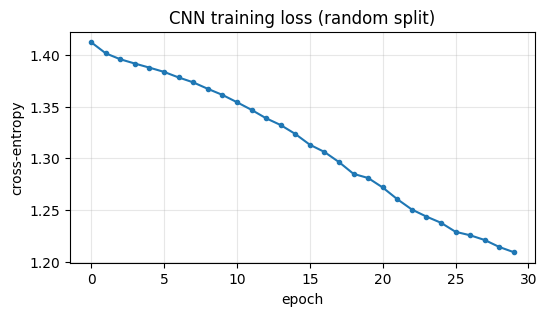

In [13]:
# CNN on the same random split (helper standardises internally)
cnn_pred, cnn_fit, cnn_losses = train_cnn(Xw[idx_tr], yw[idx_tr], Xw[idx_te], yw[idx_te])
cnn_acc = accuracy_score(y_te, cnn_pred)
cnn_bal = balanced_accuracy_score(y_te, cnn_pred)
cnn_f1  = f1_score(y_te, cnn_pred, average='macro')
print(f'{"CNN (2-conv)":26s} acc={cnn_acc:.3f}  balanced={cnn_bal:.3f}  '
      f'macroF1={cnn_f1:.3f}  (train {cnn_fit:.1f}s)')

plt.figure(figsize=(6, 3))
plt.plot(cnn_losses, '.-')
plt.title('CNN training loss (random split)'); plt.xlabel('epoch'); plt.ylabel('cross-entropy')
plt.grid(alpha=0.3); plt.show()

results['CNN (2-conv)'] = dict(model=None, pred=cnn_pred,
                               acc=cnn_acc, bal=cnn_bal, f1=cnn_f1, fit_s=cnn_fit)

## Step 8 — Random-split results: summary table, bar chart, confusion matrices

In [14]:
summary = pd.DataFrame(
    {name: {'accuracy': r['acc'], 'balanced acc': r['bal'], 'macro F1': r['f1'],
            'train time (s)': round(r['fit_s'], 2)}
     for name, r in results.items()}).T.sort_values('balanced acc', ascending=False)
summary

,accuracy,balanced acc,macro F1,train time (s)
Hist Gradient Boosting,0.803419,0.801852,0.804451,0.69
Random Forest,0.726496,0.725926,0.728448,0.56
MLP (64-32),0.709402,0.712037,0.703847,0.33
Logistic Regression,0.658120,0.660185,0.658220,0.04
Linear SVM,0.658120,0.659259,0.657441,0.04
KNN (k=5),0.581197,0.578704,0.582234,0.00
CNN (2-conv),0.350427,0.358333,0.249311,2.74


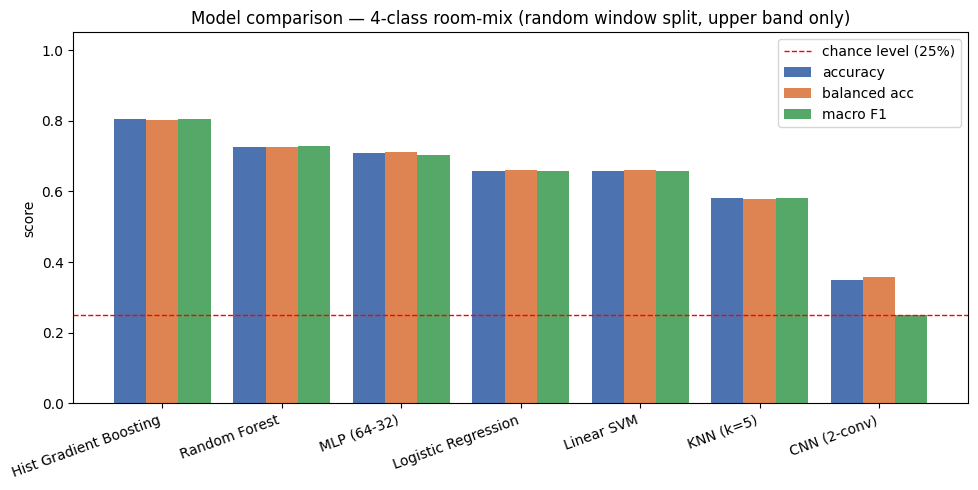

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
order = summary.index.tolist()
xpos = np.arange(len(order))
w = 0.27
ax.bar(xpos - w, summary['accuracy'],     w, label='accuracy',     color='#4c72b0')
ax.bar(xpos,      summary['balanced acc'], w, label='balanced acc', color='#dd8452')
ax.bar(xpos + w,  summary['macro F1'],     w, label='macro F1',     color='#55a868')
ax.axhline(1/4, ls='--', c='red', lw=1, label='chance level (25%)')
ax.set_xticks(xpos, order, rotation=20, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('score')
ax.set_title('Model comparison — 4-class room-mix (random window split, upper band only)')
ax.legend(); plt.tight_layout(); plt.show()

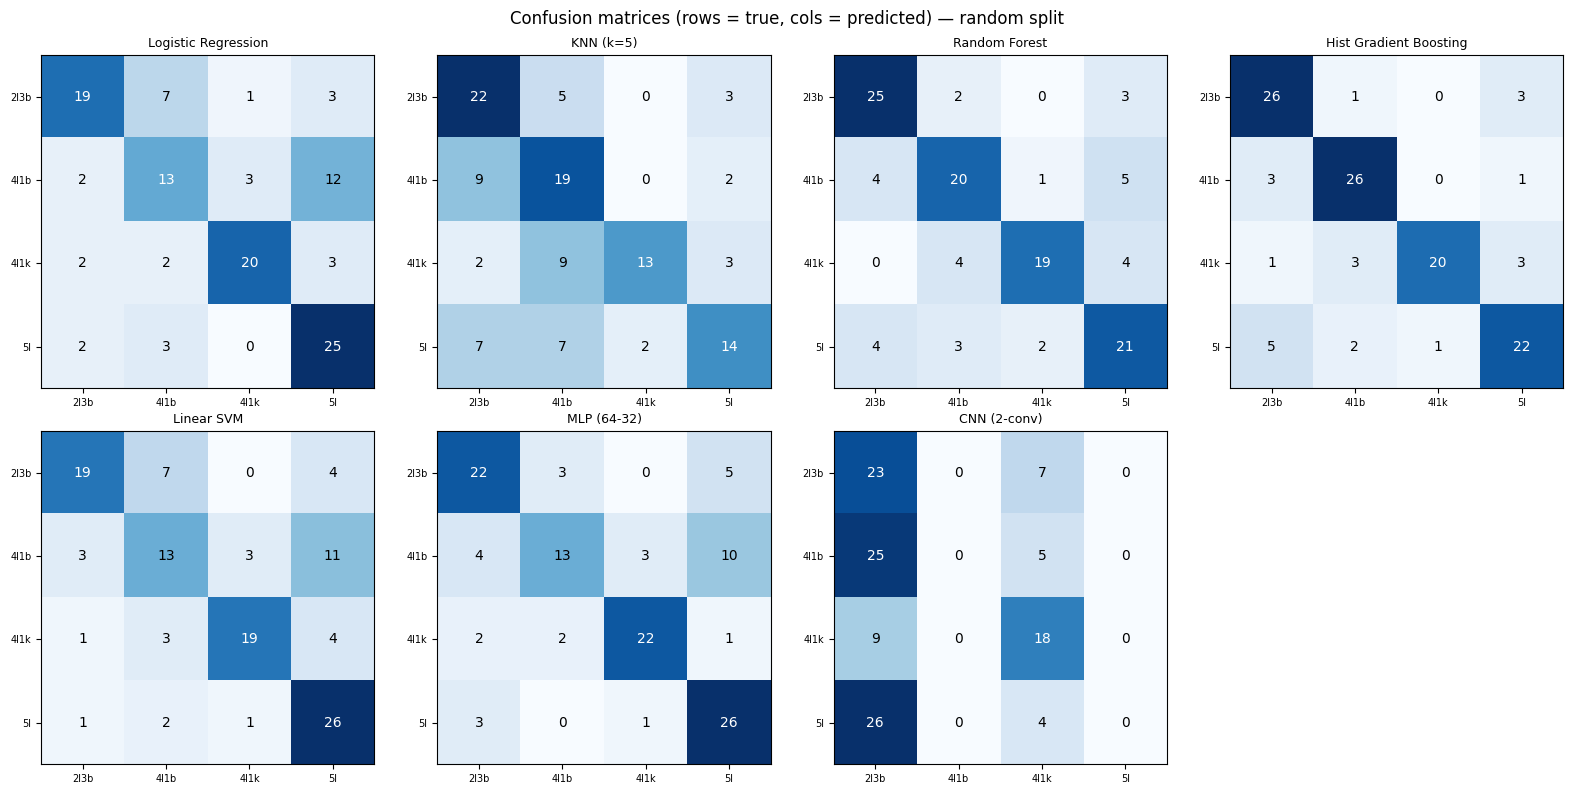

In [16]:
n = len(CLASS_ORDER)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    cm = confusion_matrix(y_te, r['pred'], labels=range(n))
    im = ax.imshow(cm, cmap='Blues')
    for i in range(n):
        for j in range(n):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    ax.set_xticks(range(n), CLASS_ORDER, fontsize=7)
    ax.set_yticks(range(n), CLASS_ORDER, fontsize=7)
    ax.set_title(name, fontsize=9)
for ax in axes.ravel()[len(results):]:
    ax.axis('off')
fig.suptitle('Confusion matrices (rows = true, cols = predicted) — random split')
plt.tight_layout(); plt.show()

## Step 9 — Evaluation B: Leave-One-Recording-Out (LORO) cross-validation
The honest test: train on 3 recordings, predict the 4th (held-out) one — the model
must generalise to an unseen session, exactly what a deployed detector has to do.
Every recording is held out once; we report balanced accuracy per held-out recording
and the mean across folds. (Chance level = 25 %.)

> **What to expect with only ONE session per configuration:** each 60 s capture has
> its own channel "fingerprint" (exact body positions, multipath, hardware state),
> so the four recordings form four tight, well-separated clusters in feature space.
> A model trained on three clusters sees the held-out cluster as *unfamiliar data*
> and tends to map all of it onto the nearest training class — giving **0.00 balanced
> accuracy on the held-out class** (it is never predicted). That is the well-known
> **cross-session domain-shift problem** of CSI sensing, and it is what this
> evaluation exposes. Step 9b adds a middle-ground test that removes the domain
> shift while still forbidding window overlap.

In [17]:
model_names = list(MODELS.keys()) + ['CNN (2-conv)']
loro = {name: {} for name in model_names}     # model -> {held-out recording: (bal, acc, f1)}

for fold, (tr_i, te_i) in enumerate(LeaveOneGroupOut().split(X, y, groups=g)):
    held = CLASS_ORDER[g[te_i][0]]
    X_tr_f, X_te_f, y_tr_f, y_te_f = X[tr_i], X[te_i], y[tr_i], y[te_i]
    for name in MODELS:
        m = clone(MODELS[name])
        m.fit(X_tr_f, y_tr_f)
        p = m.predict(X_te_f)
        if name == 'Random Forest':
            results_pred_dist = p
        loro[name][held] = (balanced_accuracy_score(y_te_f, p),
                            accuracy_score(y_te_f, p),
                            f1_score(y_te_f, p, average='macro'))
    p, _, _ = train_cnn(Xw[tr_i], yw[tr_i], Xw[te_i], yw[te_i])
    loro['CNN (2-conv)'][held] = (balanced_accuracy_score(y_te_f, p),
                                  accuracy_score(y_te_f, p),
                                  f1_score(y_te_f, p, average='macro'))
    pdist = np.bincount(results_pred_dist, minlength=len(CLASS_ORDER))
    print(f'fold {fold+1}/4 — held out: {held}  '
          + '  '.join(f'{nm.split()[0][:4]}={loro[nm][held][0]:.2f}' for nm in model_names)
          + '\n            (RF predictions on held-out windows -> {} = counts of {})'.format(pdist.tolist(), CLASS_ORDER))

loro_bal = pd.DataFrame({nm: {rec: v[0] for rec, v in d.items()}
                         for nm, d in loro.items()}).T[CLASS_ORDER]
loro_bal['mean'] = loro_bal.mean(axis=1)
loro_summary = loro_bal.sort_values('mean', ascending=False)
print('\nLORO balanced accuracy (columns = held-out recording):')
loro_summary.round(3)

/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


fold 1/4 — held out: 2l3b  Logi=0.00  KNN=0.00  Rand=0.00  Hist=0.00  Line=0.00  MLP=0.00  CNN=0.00
            (RF predictions on held-out windows -> [0, 48, 1, 51] = counts of ['2l3b', '4l1b', '4l1k', '5l'])


... (13 outputs left out)

/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


fold 4/4 — held out: 5l  Logi=0.00  KNN=0.00  Rand=0.00  Hist=0.00  Line=0.00  MLP=0.00  CNN=0.00
            (RF predictions on held-out windows -> [31, 54, 15, 0] = counts of ['2l3b', '4l1b', '4l1k', '5l'])

LORO balanced accuracy (columns = held-out recording):


/home/muditha/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,2l3b,4l1b,4l1k,5l,mean
Logistic Regression,0.0,0.0,0.0,0.0,0.0
KNN (k=5),0.0,0.0,0.0,0.0,0.0
Random Forest,0.0,0.0,0.0,0.0,0.0
Hist Gradient Boosting,0.0,0.0,0.0,0.0,0.0
Linear SVM,0.0,0.0,0.0,0.0,0.0
MLP (64-32),0.0,0.0,0.0,0.0,0.0
CNN (2-conv),0.0,0.0,0.0,0.0,0.0


In [18]:
# Per-fold detail for the best LORO model: accuracy / macro-F1 too
best_loro = loro_summary.index[0]
detail = pd.DataFrame({rec: {'balanced acc': v[0], 'accuracy': v[1], 'macro F1': v[2]}
                       for rec, v in loro[best_loro].items()}).T
print(f'Best LORO model: {best_loro}')
detail.round(3)

Best LORO model: Logistic Regression


,balanced acc,accuracy,macro F1
2l3b,0.0,0.0,0.0
4l1b,0.0,0.0,0.0
4l1k,0.0,0.0,0.0
5l,0.0,0.0,0.0


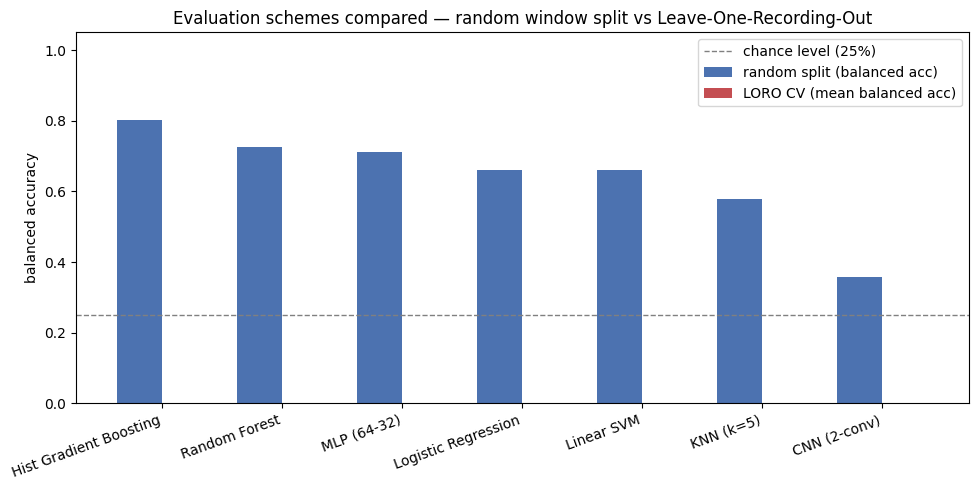

Gap (random − LORO) per model: [0.802, 0.726, 0.712, 0.66, 0.659, 0.579, 0.358]
A large gap = the model memorises the session instead of learning the room-mix signal.


In [19]:
# Side-by-side: optimistic random split vs honest LORO
fig, ax = plt.subplots(figsize=(10, 5))
names = summary.index.tolist()
xpos = np.arange(len(names))
w = 0.38
rand_bal = [results[nm]['bal'] for nm in names]
loro_mean = [loro_bal.loc[nm, 'mean'] for nm in names]
ax.bar(xpos - w/2, rand_bal,  w, label='random split (balanced acc)', color='#4c72b0')
ax.bar(xpos + w/2, loro_mean, w, label='LORO CV (mean balanced acc)', color='#c44e52')
ax.axhline(1/4, ls='--', c='gray', lw=1, label='chance level (25%)')
ax.set_xticks(xpos, names, rotation=20, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('balanced accuracy')
ax.set_title('Evaluation schemes compared — random window split vs Leave-One-Recording-Out')
ax.legend(); plt.tight_layout(); plt.show()

gap = np.array(rand_bal) - np.array(loro_mean)
print('Gap (random − LORO) per model:', np.round(gap, 3).tolist())
print('A large gap = the model memorises the session instead of learning the room-mix signal.')

## Step 9b — Evaluation C: time-block split (no overlap, same sessions)
Train on the **first 70 % of every recording**, test on the **last 30 %**, and drop
any test window that shares frames with a training window (100-frame guard). This
keeps the session distribution identical (no domain shift) but removes the
window-overlap leakage of Step 7 — the realistic "keep watching the same room" test.

In [20]:
def window_features_span(U, rssi, lo, hi):
    """window_features() restricted to frames [lo, hi) so train/test never share frames."""
    rows = []
    for s in range(lo, max(lo, hi) - WINDOW_FRAMES + 1, STRIDE_FRAMES):
        w = U[s:s + WINDOW_FRAMES]
        d = np.diff(w, axis=0)
        rows.append(np.concatenate([
            w.mean(axis=0), w.std(axis=0),
            w.max(axis=0) - w.min(axis=0), d.std(axis=0),
            [rssi[s:s + WINDOW_FRAMES].mean(), rssi[s:s + WINDOW_FRAMES].std()]]))
    return np.asarray(rows, np.float32)

def window_matrix_span(U, lo, hi):
    return np.stack([U[s:s + WINDOW_FRAMES]
                     for s in range(lo, max(lo, hi) - WINDOW_FRAMES + 1, STRIDE_FRAMES)])

Xb_tr_l, yb_tr_l, Xb_te_l, yb_te_l, Xw_tr_l, Xw_te_l, blk_id = [], [], [], [], [], [], []
for k, name in enumerate(CLASS_ORDER):
    f = frames[name]
    n = len(f['U'])
    cut = int(0.7 * n)                       # frame boundary between train and test
    Xtr = window_features_span(f['U'], f['rssi'], 0, cut)
    Xte = window_features_span(f['U'], f['rssi'], cut + WINDOW_FRAMES, n)
    Xb_tr_l.append(Xtr);  yb_tr_l.append(np.full(len(Xtr), k))
    Xb_te_l.append(Xte);  yb_te_l.append(np.full(len(Xte), k))
    Xw_tr_l.append(window_matrix_span(f['U'], 0, cut))
    Xw_te_l.append(window_matrix_span(f['U'], cut + WINDOW_FRAMES, n))
    blk_id.append(np.full(len(Xte), k))
    print(f'{name:6s}: {len(Xtr):3d} train windows (0-{cut}s-ish) | '
          f'{len(Xte):3d} test windows (guard gap of {WINDOW_FRAMES} frames)')

Xb_tr = np.vstack(Xb_tr_l); yb_tr = np.concatenate(yb_tr_l)
Xb_te = np.vstack(Xb_te_l); yb_te = np.concatenate(yb_te_l)
Xwb_tr = np.vstack(Xw_tr_l); Xwb_te = np.vstack(Xw_te_l)

blk = {}
for name, model in MODELS.items():
    m = clone(model); m.fit(Xb_tr, yb_tr)
    p = m.predict(Xb_te)
    blk[name] = (balanced_accuracy_score(yb_te, p), p)
p, _, _ = train_cnn(Xwb_tr, yb_tr, Xwb_te, yb_te)
blk['CNN (2-conv)'] = (balanced_accuracy_score(yb_te, p), p)

blk_df = pd.DataFrame({'balanced acc': {nm: v[0] for nm, v in blk.items()}}
                      ).sort_values('balanced acc', ascending=False)
print('\\nTime-block split results:')
blk_df.round(3)

2l3b  :  69 train windows (0-3537s-ish) |  27 test windows (guard gap of 100 frames)
4l1b  :  69 train windows (0-3504s-ish) |  27 test windows (guard gap of 100 frames)
4l1k  :  61 train windows (0-3132s-ish) |  23 test windows (guard gap of 100 frames)
5l    :  70 train windows (0-3556s-ish) |  27 test windows (guard gap of 100 frames)


\nTime-block split results:


,balanced acc
MLP (64-32),0.638
Hist Gradient Boosting,0.628
Random Forest,0.609
Logistic Regression,0.548
Linear SVM,0.513
KNN (k=5),0.444
CNN (2-conv),0.319


## Step 10 — Conclusions & next steps

In [21]:
# One compact leaderboard combining both evaluations
leaderboard = pd.DataFrame({
    'random-split balanced acc': {nm: results[nm]['bal'] for nm in model_names},
    'LORO mean balanced acc':    loro_bal['mean'],
    'time-block balanced acc':   {nm: blk[nm][0] for nm in model_names},
}).sort_values('time-block balanced acc', ascending=False)
leaderboard.round(3)

,random-split balanced acc,LORO mean balanced acc,time-block balanced acc
MLP (64-32),0.712,0.0,0.638
Hist Gradient Boosting,0.802,0.0,0.628
Random Forest,0.726,0.0,0.609
Logistic Regression,0.660,0.0,0.548
Linear SVM,0.659,0.0,0.513
KNN (k=5),0.579,0.0,0.444
CNN (2-conv),0.358,0.0,0.319


### What the four recordings showed (results above)

- **Yes, the extractions differ.** All four classes are separable *within* a session:
  the random window split reaches **80.2 % balanced accuracy** (Hist Gradient Boosting),
  and even with the stricter time-block split (train on first 70 % of each recording,
  never overlapping frames) the best models still reach **~61-64 %** (MLP 63.8 %,
  HistGB 62.8 %, RF 60.9 %) — far above the 25 % chance line. The room mix *does*
  change the CSI pattern, mostly through the spectral shape and motion profile.
- **But models memorise the session, not the room-mix.** Under **LORO every model
  scores 0.00**: the held-out class is never predicted — e.g. all `5l` windows were
  mapped onto `2l3b`/`4l1b`. Each 60 s capture is its own tight cluster in feature
  space (body positions + multipath fingerprint), so with only **one session per
  configuration** cross-session generalisation is not learnable from this data yet.
  This is the classic **cross-session / domain-shift problem** in CSI sensing.
- **Model ranking is consistent** across both leakage-free schemes (random &
  time-block): tree ensembles + MLP > linear models > KNN; the tiny CNN underperforms
  (30 % of the data, no augmentation, 30 epochs) — it needs more data/capacity.
- **`4l1k` is the distinctive one**: its summary table shows the lowest mean amplitude
  (27.3 vs ~28.7) and the largest RSSI spread (std 2.1 vs 0.6-0.8), i.e. the kitchen
  person changes the channel noticeably more than the bedroom person.

### Next steps to fix the LORO collapse
1. **Collect 2-3 repeats per configuration** (different days/positions). With only
   one session per class, LORO = "predict an unseen domain" — impossible to learn.
   Repeats let the model average out the session fingerprint.
2. **Per-session normalisation / feature whitening** (e.g. subtract each session's
   own mean-std before training, or contrastive domain adaptation) — reduces the
   cluster separation that currently dominates.
3. Add **relative** features only (spectral shape ratio, motion profile) — tried
   informally: still 0.00, confirming the bottleneck is session identity, not
   absolute amplitude.
4. Vary total people count too (e.g. `2l`, `3l1b`) so the model cannot exploit the
   fixed "always 5 bodies" structure.
5. Revisit the CNN with the time-block split, more epochs, and light augmentation
   (time-shift / noise) once more sessions exist.
6. Cross-dataset transfer test against `rawData` (old receiver position) to measure
   how position change affects the same models.